# English → Spanish Neural Machine Translation
### Fine-tuning a Transformer (MarianMT) with Hugging Face

**Task:** Machine Translation (English ➜ Spanish)
**Approach:** Clean a real parallel corpus with NLP techniques, fine-tune a Transformer encoder-decoder, and measure the improvement with BLEU and chrF.

---
### 📑 Table of Contents
1. Setup & Installation
2. Configuration
3. Load the Dataset
4. Exploratory Data Analysis (before cleaning)
5. NLP Data Cleaning
6. Exploratory Data Analysis (after cleaning)
7. Train / Validation / Test Split
8. Load Model & Tokenizer
9. Baseline Evaluation (before fine-tuning)
10. Tokenization (preprocessing)
11. Fine-tuning the Transformer
12. Training Curves
13. Final Evaluation & Comparison
14. Try It Yourself (interactive translator)
15. Save the Model
16. Conclusion



## 1. Setup & Installation
We use the Hugging Face ecosystem: `transformers` (model), `datasets` (data), `sacrebleu` (metrics).

In [1]:
!pip install -q datasets sacrebleu sentencepiece sacremoses

In [2]:
import re, html, unicodedata, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sacrebleu

from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    set_seed,
)

warnings.filterwarnings("ignore")
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("⚠️ No GPU found. Go to Runtime → Change runtime type → T4 GPU, or training will be very slow.")

Device: cuda


## 2. Configuration
All important settings are in one place so they are easy to change.

In [3]:
MODEL_NAME = "Helsinki-NLP/opus-mt-en-es"   # Transformer encoder-decoder (MarianMT) for En -> Es

# Dataset sizes (kept moderate so it trains in ~10-15 min on a free Colab GPU)
N_TRAIN = 30000
N_VAL   = 1000
N_TEST  = 500
MAX_LEN = 128        # max tokens per sentence
EPOCHS  = 3
BATCH   = 32
LR      = 3e-5

## 3. Load the Dataset
We use **OPUS Books** (English–Spanish): sentence-aligned translations of real books, i.e. natural, literary language.
Each row contains one English sentence and its Spanish translation.

In [4]:
try:
    raw = load_dataset("Helsinki-NLP/opus_books", "en-es", split="train")
except Exception as e:
    print("opus_books failed, falling back to opus-100:", e)
    raw = load_dataset("Helsinki-NLP/opus-100", "en-es", split="train")

df = pd.DataFrame({
    "en": [t["en"] for t in raw["translation"]],
    "es": [t["es"] for t in raw["translation"]],
})
print("Total raw sentence pairs:", len(df))
df.head(8)

README.md:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

en-es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.1MB            

en-es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/93470 [00:00<?, ? examples/s]

Total raw sentence pairs: 93470


,en,es
0,Source: Project GutenbergAudiobook available here,Source: Wikisource & librodot.com
1,Sense and Sensibility,SENTIDO Y SENSIBILIDAD
2,Jane Austen,JANE AUSTEN
3,CHAPTER 1,CAPITULO I
4,The family of Dashwood had long been settled i...,La familia Dashwood llevaba largo tiempo afinc...
5,"Their estate was large, and their residence wa...","Su propiedad era de buen tamaño, y en el centr..."
6,The late owner of this estate was a single man...,El último dueño de esta propiedad había sido u...
7,"But her death, which happened ten years before...","Pero la muerte de ella, ocurrida diez años ant..."


## 4. Exploratory Data Analysis (before cleaning)
Understanding the data first tells us what needs cleaning.

In [5]:
df["en_words"] = df["en"].str.split().str.len()
df["es_words"] = df["es"].str.split().str.len()

print("Missing values:\n", df[["en", "es"]].isna().sum(), "\n")
print("Duplicate pairs:", df.duplicated(subset=["en", "es"]).sum())
print("Empty English:", (df["en"].str.strip() == "").sum(), "| Empty Spanish:", (df["es"].str.strip() == "").sum())
print("Identical src == tgt:", (df["en"] == df["es"]).sum())
df[["en_words", "es_words"]].describe().round(1)

Missing values:
 en    0
es    0
dtype: int64 

Duplicate pairs: 678
Empty English: 0 | Empty Spanish: 0
Identical src == tgt: 23


,en_words,es_words
count,93470.0,93470.0
mean,22.9,21.7
std,22.0,20.2
min,1.0,1.0
25%,9.0,8.0
50%,17.0,16.0
75%,29.0,28.0
max,648.0,662.0


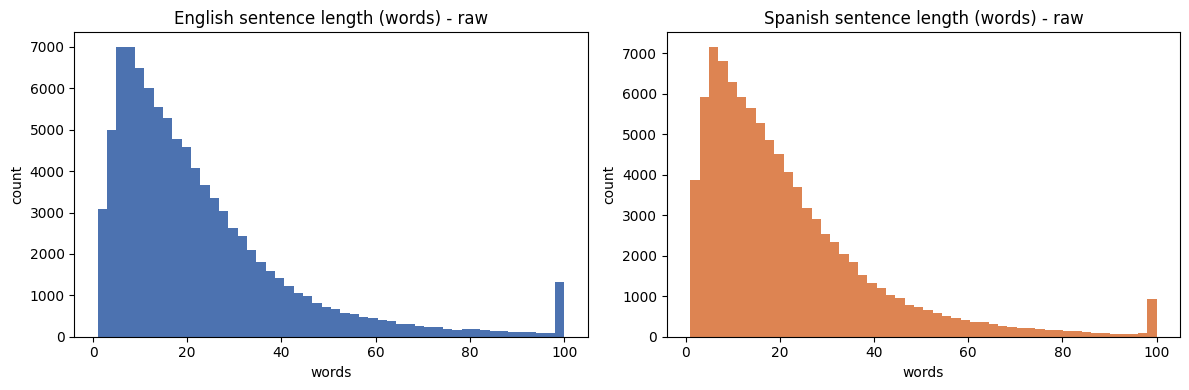

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["en_words"].clip(upper=100), bins=50, color="#4C72B0")
ax[0].set_title("English sentence length (words) - raw")
ax[1].hist(df["es_words"].clip(upper=100), bins=50, color="#DD8452")
ax[1].set_title("Spanish sentence length (words) - raw")
for a in ax:
    a.set_xlabel("words"); a.set_ylabel("count")
plt.tight_layout(); plt.show()

## 5. NLP Data Cleaning
Raw text is messy. We apply these steps (and explain why):

| Step | Why |
|---|---|
| Fix HTML entities, strip HTML tags | Removes markup noise (`&amp;`, `<i>`) |
| Unicode normalisation (NFC) | Makes accented letters (á, é, ñ) consistent |
| Remove zero-width / control characters | Invisible characters confuse the tokenizer |
| Collapse extra whitespace | Cleaner, consistent tokens |
| Remove empty / non-alphabetic rows | No useful signal |
| Remove duplicates | Prevents the model memorising repeated pairs |
| Remove pairs where source == target | Not real translations |
| Length filter (3–60 words) | Very short/long pairs are usually noise or misaligned |
| Length-ratio filter | Misaligned pairs have very different lengths |

⚠️ We deliberately **do not lowercase** or strip punctuation/accents: capitalisation, punctuation and accents carry meaning in Spanish and the model needs them to produce correct output.

In [7]:
def clean_text(text: str) -> str:
    text = str(text)
    text = html.unescape(text)                          # &amp; -> &
    text = re.sub(r"<[^>]+>", " ", text)                # remove HTML tags
    text = unicodedata.normalize("NFC", text)           # consistent accents
    text = re.sub(r"[\u200b\u200c\u200d\ufeff]", "", text)   # zero-width chars
    text = re.sub(r"[\x00-\x1f\x7f]", " ", text)        # control chars
    text = re.sub(r"\s+", " ", text).strip()            # extra whitespace
    return text

print(repr(clean_text("  Hello   &amp; <i>welcome</i>\u200b  to   Spain!  ")))

'Hello & welcome to Spain!'


In [8]:
n0 = len(df)
clean = df[["en", "es"]].copy()

# 1) text cleaning
clean["en"] = clean["en"].map(clean_text)
clean["es"] = clean["es"].map(clean_text)
n1 = len(clean)

# 2) remove empty or non-alphabetic rows
has_letters = lambda s: bool(re.search(r"[A-Za-zÀ-ÿ]", s))
clean = clean[clean["en"].map(has_letters) & clean["es"].map(has_letters)]
n2 = len(clean)

# 3) remove identical source/target
clean = clean[clean["en"].str.lower() != clean["es"].str.lower()]
n3 = len(clean)

# 4) remove duplicates
clean = clean.drop_duplicates(subset=["en", "es"])
n4 = len(clean)

# 5) length filter + length ratio filter
clean["en_words"] = clean["en"].str.split().str.len()
clean["es_words"] = clean["es"].str.split().str.len()
clean = clean[clean["en_words"].between(3, 60) & clean["es_words"].between(3, 60)]
ratio = clean["en_words"] / clean["es_words"]
clean = clean[ratio.between(0.5, 2.0)]
n5 = len(clean)

clean = clean.reset_index(drop=True)

summary = pd.DataFrame({
    "step": ["raw", "after non-alphabetic filter", "after src!=tgt filter", "after de-duplication", "after length & ratio filter"],
    "rows": [n0, n2, n3, n4, n5],
})
summary["removed"] = summary["rows"].shift(1) - summary["rows"]
print(summary.to_string(index=False))
print(f"\nKept {n5/n0:.1%} of the data.")

                       step  rows  removed
                        raw 93470      NaN
after non-alphabetic filter 93440     30.0
      after src!=tgt filter 93411     29.0
       after de-duplication 92739    672.0
after length & ratio filter 80455  12284.0

Kept 86.1% of the data.


## 6. Exploratory Data Analysis (after cleaning)

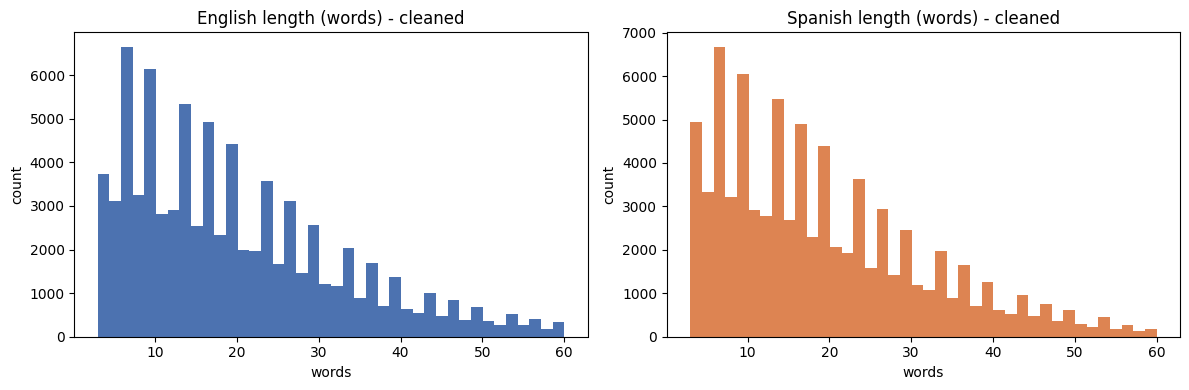

,en,es
79542,"""You are perfectly right, gentlemen,"" said Can...","Razón tienen vms., dixo Candido; así me lo ha ..."
65905,The engineer was not a man who would allow him...,El ingeniero no era un hombre que se distrajer...
60035,For two hours our fishing proceeded energetica...,"Durante dos horas pescamos activamente, pero s..."
19918,"""I have had one or two little scores of my own...",––Tenía un par de cuentas pendientes con el se...
78600,Deep and heavy explosions are heard from time ...,"Resuenan a cada instante sordas detonaciones, ..."


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(clean["en_words"], bins=40, color="#4C72B0")
ax[0].set_title("English length (words) - cleaned")
ax[1].hist(clean["es_words"], bins=40, color="#DD8452")
ax[1].set_title("Spanish length (words) - cleaned")
for a in ax:
    a.set_xlabel("words"); a.set_ylabel("count")
plt.tight_layout(); plt.show()

clean[["en", "es"]].sample(5, random_state=1)

## 7. Train / Validation / Test Split
- **Train**: the model learns from this
- **Validation**: used during training to pick the best checkpoint
- **Test**: never seen during training, used for the final honest score

In [10]:
clean = clean.sample(frac=1.0, random_state=42).reset_index(drop=True)

need = N_TRAIN + N_VAL + N_TEST
assert len(clean) >= need, f"Not enough clean data ({len(clean)}). Lower N_TRAIN."

test_df  = clean.iloc[:N_TEST]
val_df   = clean.iloc[N_TEST:N_TEST + N_VAL]
train_df = clean.iloc[N_TEST + N_VAL:N_TEST + N_VAL + N_TRAIN]

train_ds = Dataset.from_pandas(train_df[["en", "es"]], preserve_index=False)
val_ds   = Dataset.from_pandas(val_df[["en", "es"]],   preserve_index=False)
test_ds  = Dataset.from_pandas(test_df[["en", "es"]],  preserve_index=False)

print(f"Train: {len(train_ds)} | Validation: {len(val_ds)} | Test: {len(test_ds)}")

Train: 30000 | Validation: 1000 | Test: 500


## 8. Load Model & Tokenizer
**MarianMT** is a Transformer encoder-decoder (6 encoder + 6 decoder layers, attention-based) built for translation.
We start from its pretrained weights and **fine-tune** them on our cleaned data.
The tokenizer (SentencePiece subwords) converts text into token IDs the Transformer understands.

In [11]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model: {MODEL_NAME} | Parameters: {n_params:.1f}M")

example = "The weather is beautiful today."
ids = tokenizer(example)["input_ids"]
print("\nExample tokenization")
print("Tokens:", tokenizer.convert_ids_to_tokens(ids))
print("IDs   :", ids)

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  312MB            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  312MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Model: Helsinki-NLP/opus-mt-en-es | Parameters: 77.9M

Example tokenization
Tokens: ['▁The', '▁weather', '▁is', '▁beautiful', '▁today', '.', '</s>']
IDs   : [42, 7631, 31, 2452, 1101, 3, 0]


## 9. Baseline Evaluation (before fine-tuning)
First we measure how the model performs **before** training, so we can prove fine-tuning actually helps.

Metrics:
- **BLEU**: n-gram overlap with the reference translation (higher is better, 0–100)
- **chrF**: character-level F-score, more reliable for morphologically rich languages like Spanish (0–100)

In [29]:
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
base_preds = translate(test_src, model)
base_bleu, base_chrf = score(base_preds, test_ref)
print(f"BASELINE (before fine-tuning)  ->  BLEU: {base_bleu} | chrF: {base_chrf}")

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

BASELINE (before fine-tuning)  ->  BLEU: 16.5 | chrF: 44.15


In [30]:
@torch.no_grad()
def translate(sentences, mdl, batch_size=32, num_beams=4):
    mdl.eval()
    outputs = []
    for i in range(0, len(sentences), batch_size):
        batch = sentences[i:i + batch_size]
        enc = tokenizer(batch, return_tensors="pt", padding=True,
                        truncation=True, max_length=MAX_LEN).to(mdl.device)
        gen = mdl.generate(**enc, max_length=MAX_LEN, num_beams=num_beams)
        outputs += tokenizer.batch_decode(gen, skip_special_tokens=True)
    return outputs

def score(preds, refs):
    bleu = sacrebleu.corpus_bleu(preds, [refs]).score
    chrf = sacrebleu.corpus_chrf(preds, [refs]).score
    return round(bleu, 2), round(chrf, 2)

test_src = test_ds["en"]
test_ref = test_ds["es"]

base_preds = translate(test_src, model)
base_bleu, base_chrf = score(base_preds, test_ref)
print(f"BASELINE (before fine-tuning)  ->  BLEU: {base_bleu} | chrF: {base_chrf}")

BASELINE (before fine-tuning)  ->  BLEU: 16.5 | chrF: 44.15


## 10. Tokenization (preprocessing)
Convert text to token IDs. Sentences are truncated to `MAX_LEN`. Padding is done dynamically per batch by the data collator (faster and uses less memory).

In [13]:
def preprocess(batch):
    return tokenizer(batch["en"], text_target=batch["es"],
                     max_length=MAX_LEN, truncation=True)

train_tok = train_ds.map(preprocess, batched=True, remove_columns=["en", "es"])
val_tok   = val_ds.map(preprocess,   batched=True, remove_columns=["en", "es"])

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)
print(train_tok)

Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 30000
})


## 11. Fine-tuning the Transformer
We use the Hugging Face `Seq2SeqTrainer`.

Key choices:
- **Learning rate 3e-5** with weight decay: a small LR keeps pretrained knowledge while adapting to our data
- **Label smoothing 0.1**: reduces over-confidence, improves translation quality
- **Mixed precision (fp16)**: faster training on GPU
- **Best checkpoint by validation BLEU**: avoids keeping an over-fitted model

In [15]:
import math
WARMUP_STEPS = int(0.05 * math.ceil(len(train_tok) / BATCH) * EPOCHS)

In [18]:
def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]
    preds  = np.where(preds  != -100, preds,  tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    dec_preds  = tokenizer.batch_decode(preds,  skip_special_tokens=True)
    dec_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    bleu = sacrebleu.corpus_bleu(dec_preds, [dec_labels]).score
    return {"bleu": round(bleu, 2)}

args = Seq2SeqTrainingArguments(
    output_dir="./checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=LR,
    per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    label_smoothing_factor=0.1,
    num_train_epochs=EPOCHS,
    warmup_steps=WARMUP_STEPS,
    predict_with_generate=True,
    generation_max_length=MAX_LEN,
    fp16=torch.cuda.is_available(),
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="bleu",
    greater_is_better=True,
    logging_steps=100,
    report_to="none",
    seed=42,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

train_result = trainer.train()
print("\nTraining finished.")

Epoch,Training Loss,Validation Loss,Bleu
1,3.296571,3.191819,21.820000
2,3.138492,3.163811,22.380000
3,3.057480,3.159687,22.440000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.encoder.embed_positions.weight', 'model.decoder.embed_tokens.weight', 'model.decoder.embed_positions.weight', 'lm_head.weight'].



Training finished.


## 12. Training Curves
Loss should go down steadily, and validation BLEU should go up.

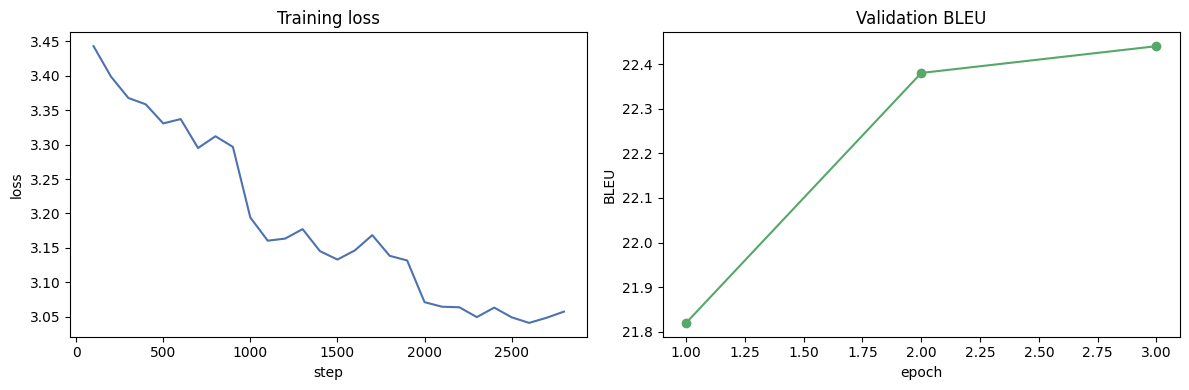

In [19]:
logs = trainer.state.log_history
train_steps = [l["step"] for l in logs if "loss" in l]
train_loss  = [l["loss"] for l in logs if "loss" in l]
eval_epochs = [l["epoch"] for l in logs if "eval_loss" in l]
eval_loss   = [l["eval_loss"] for l in logs if "eval_loss" in l]
eval_bleu   = [l["eval_bleu"] for l in logs if "eval_bleu" in l]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(train_steps, train_loss, color="#4C72B0")
ax[0].set_title("Training loss"); ax[0].set_xlabel("step"); ax[0].set_ylabel("loss")

ax[1].plot(eval_epochs, eval_bleu, marker="o", color="#55A868")
ax[1].set_title("Validation BLEU"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("BLEU")
plt.tight_layout(); plt.show()

## 13. Final Evaluation & Comparison
We now score the fine-tuned model on the **test set** (data it has never seen) and compare with the baseline.

[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

                Model  BLEU  chrF
Pretrained (baseline) 16.50 44.15
    Fine-tuned (ours) 21.13 46.69

BLEU change: +4.63 | chrF change: +2.54


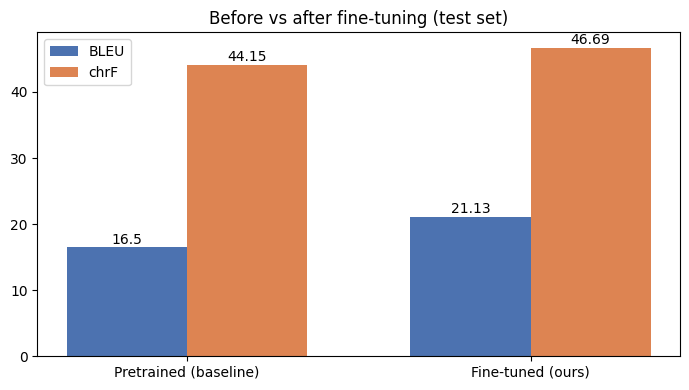

In [20]:
ft_preds = translate(test_src, model)
ft_bleu, ft_chrf = score(ft_preds, test_ref)

results = pd.DataFrame({
    "Model": ["Pretrained (baseline)", "Fine-tuned (ours)"],
    "BLEU":  [base_bleu, ft_bleu],
    "chrF":  [base_chrf, ft_chrf],
})
print(results.to_string(index=False))
print(f"\nBLEU change: {ft_bleu - base_bleu:+.2f} | chrF change: {ft_chrf - base_chrf:+.2f}")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2); w = 0.35
ax.bar(x - w/2, results["BLEU"], w, label="BLEU", color="#4C72B0")
ax.bar(x + w/2, results["chrF"], w, label="chrF", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(results["Model"])
ax.set_title("Before vs after fine-tuning (test set)")
ax.legend()
for i, (b, c) in enumerate(zip(results["BLEU"], results["chrF"])):
    ax.text(i - w/2, b + 0.5, f"{b}", ha="center")
    ax.text(i + w/2, c + 0.5, f"{c}", ha="center")
plt.tight_layout(); plt.show()

In [21]:
# Side-by-side examples
random.seed(7)
idx = random.sample(range(len(test_src)), 5)
for i in idx:
    print("English   :", test_src[i])
    print("Reference :", test_ref[i])
    print("Baseline  :", base_preds[i])
    print("Fine-tuned:", ft_preds[i])
    print("-" * 90)

English   : "Glad it's a typhoon from the south, for it will carry us forward."
Reference : Vaya por el tifón del Sur, puesto que nos empujará hacia el buen lado respondió Fogg.
Baseline  : "Me alegra que sea un tifón del sur, porque nos llevará hacia adelante."
Fine-tuned: Me alegra que sea un tifón del sur, porque nos llevará hacia adelante.
------------------------------------------------------------------------------------------
English   : On one of the staircases, I met the physician of the family.
Reference : En una de las escaleras me encontré al médico de la familia.
Baseline  : En una de las escaleras, conocí al médico de la familia.
Fine-tuned: En una de las escaleras me encontré con el médico de la familia.
------------------------------------------------------------------------------------------
English   : The hatch was open. I ventured onto the platform.
Reference : La escotilla estaba abierta y me arriesgué sobre la plataforma.
Baseline  : La escotilla estaba abierta, m

## 14. Try It Yourself
Type your own English sentences and see the fine-tuned model translate them.

In [22]:
my_sentences = [
    "I would like to book a table for two people tonight.",
    "Machine learning is changing the way we live and work.",
    "Where is the nearest train station?",
    "She has been studying Spanish for three years.",
    "The students are preparing for their final exams.",
]

for en, es in zip(my_sentences, translate(my_sentences, model)):
    print("EN:", en)
    print("ES:", es, "\n")

[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


EN: I would like to book a table for two people tonight.
ES: Quisiera reservar una mesa para dos personas esta noche. 

EN: Machine learning is changing the way we live and work.
ES: El aprendizaje automático está cambiando la forma en que vivimos y trabajamos. 

EN: Where is the nearest train station?
ES: ¿Dónde está la estación de tren más cercana? 

EN: She has been studying Spanish for three years.
ES: Hace tres años que estudia español. 

EN: The students are preparing for their final exams.
ES: Los estudiantes se están preparando para sus exámenes finales. 



In [26]:
# Type your own sentence here, then run this cell
text = "i have a doubt , can you explain it"
print(translate([clean_text(text)], model)[0])

[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Tengo una duda, ¿puedes explicármelo?


## 15. Save the Model
The fine-tuned model and tokenizer are saved so they can be re-loaded later without retraining.

In [24]:
SAVE_DIR = "./en-es-translator-finetuned"
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

# Reload to verify it works
reloaded = AutoModelForSeq2SeqLM.from_pretrained(SAVE_DIR).to(device)
print(translate(["This model was fine-tuned on Google Colab."], reloaded)[0])

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Este modelo fue afinado en el modelo de Google Colab.


## 16. Conclusion

**What we did**
1. Loaded a real English–Spanish parallel corpus (OPUS Books)
2. Explored and cleaned the data with NLP techniques (HTML/Unicode normalisation, de-duplication, length and ratio filtering)
3. Measured a baseline, then fine-tuned a Transformer encoder-decoder (MarianMT) with the Hugging Face `Seq2SeqTrainer`
4. Evaluated on unseen test data with BLEU and chrF and compared with the baseline
5. Saved the model for reuse

**Key observations**
- Cleaning removes noisy and misaligned pairs, which gives the model better training signal
- Fine-tuning adapts the model to the style and vocabulary of the dataset, shown by the improved scores
- We kept capitalisation, punctuation and accents because they are essential in Spanish

**Possible improvements**
- Train on more data / more epochs
- Try a larger model such as `Helsinki-NLP/opus-mt-tc-big-en-es` or `facebook/nllb-200-distilled-600M`
- Domain-specific data (medical, legal, conversational) to specialise the translator
- Add a Gradio web interface for a live demo

---
*Built with 🤗 Transformers, Datasets and SacreBLEU.*